In [48]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import torch
import seaborn as sns
import umap
sns.set()

import torch
from mpl_toolkits.mplot3d import Axes3D 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import rand_score
from sklearn.metrics import normalized_mutual_info_score

In [29]:
data = sc.datasets.paul15()
#print(data.shape)

print(data.obs["paul15_clusters"])

W31105      7MEP
W31106      15Mo
W31107      3Ery
W31108      15Mo
W31109      3Ery
           ...  
W39164      2Ery
W39165    13Baso
W39166      7MEP
W39167      15Mo
W39168      3Ery
Name: paul15_clusters, Length: 2730, dtype: category
Categories (19, str): ['1Ery', '2Ery', '3Ery', '4Ery', ..., '16Neu', '17Neu', '18Eos', '19Lymph']


1255


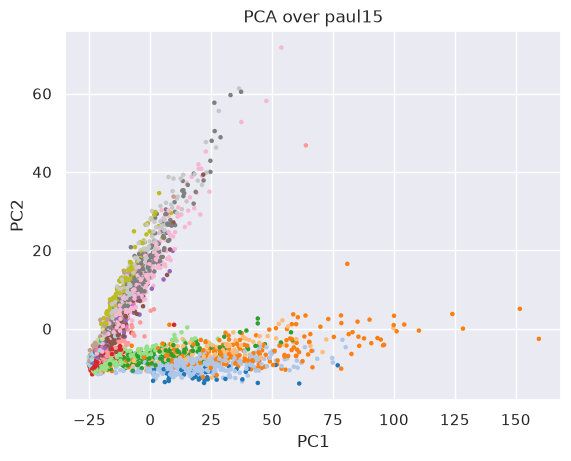

In [25]:
x = np.asarray(data.X, dtype="float32")
labels = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

pca = PCA(n_components=0.90)
pcs = pca.fit_transform(x_scaled)
print(pca.n_components_)
plt.scatter(pcs[:, 0], pcs[:, 1], c=labels, cmap="tab20", s=5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA over paul15")
plt.show()

### KMeans


/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.39344644192784123
Silhouette Score:  0.21179530024528503
Rand Index:  0.8890487062711321


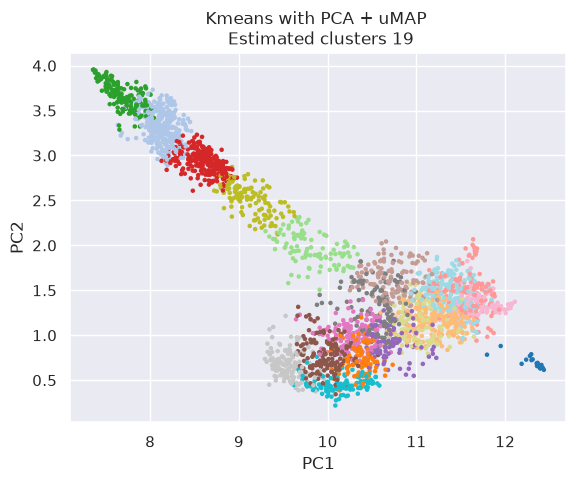

In [46]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(u)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(u, labels))
print("Rand Index: ", rand_score(y_true, labels))

plt.scatter(u[:,0],u[:,1],c=labels,cmap="tab20",s=5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Kmeans with PCA + uMAP \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.39344644192784123
Silhouette Score:  0.21179530024528503
Rand Index:  0.8890487062711321


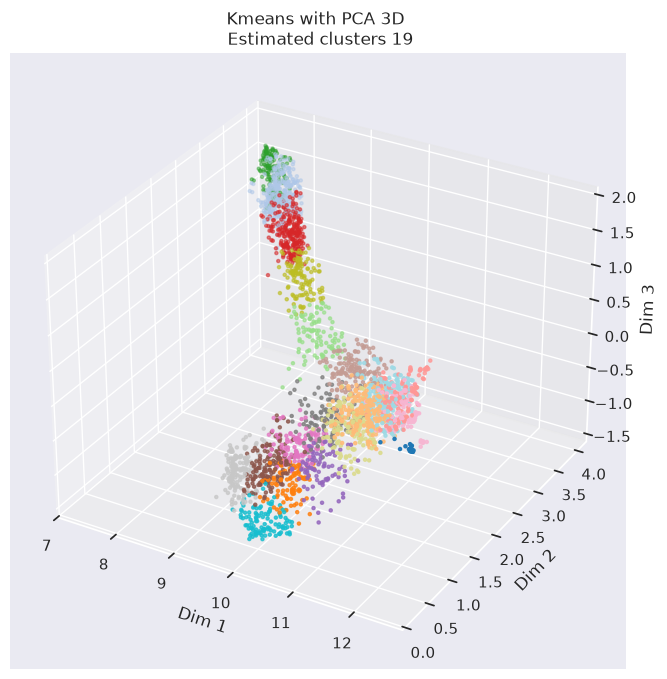

In [45]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(u)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(u, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(u[:,0],u[:,1],u[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("Kmeans with PCA 3D + uMAP \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.3948789555386492
Silhouette Score:  0.3967496156692505
Rand Index:  0.8927076831803838


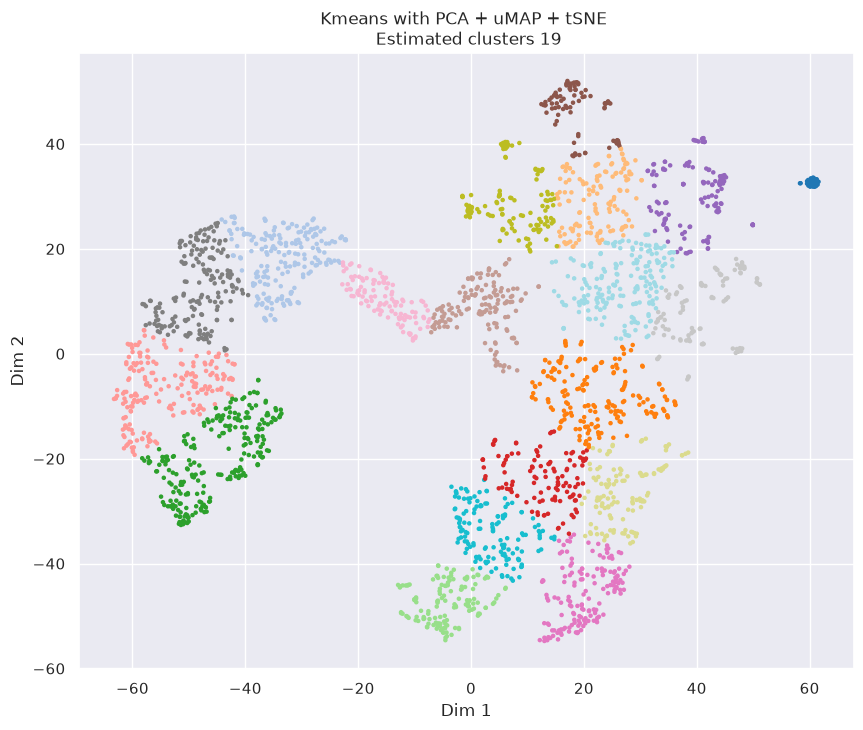

In [52]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
tsne = TSNE(n_components=2,random_state=3)
t = tsne.fit_transform(u)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(t)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(t, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
plt.scatter(t[:,0],t[:,1],c=labels,cmap="tab20",s=5)
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.title("Kmeans with PCA + uMAP + tSNE \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.38602940580042827
Silhouette Score:  0.3342972993850708
Rand Index:  0.8930878087345658


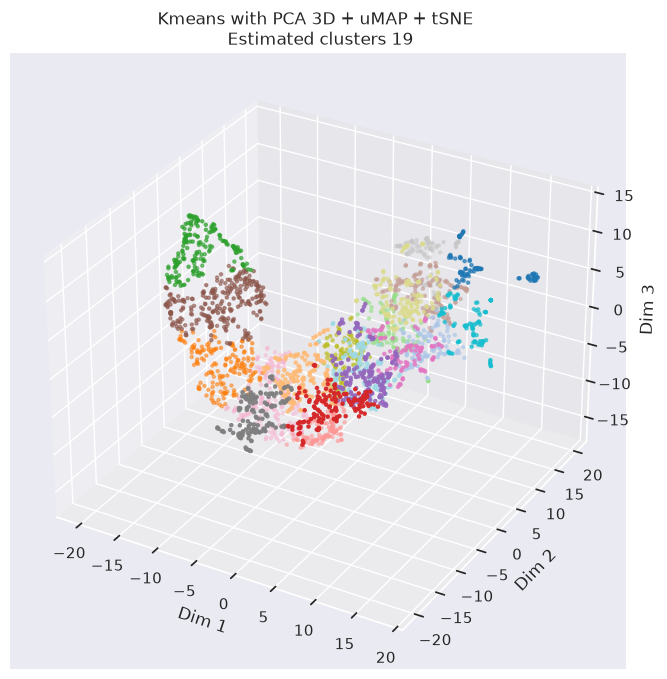

In [53]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(u)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(t)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(t, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("Kmeans with PCA 3D + uMAP + tSNE \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.3206916793294456
Silhouette Score:  0.27960723638534546
Rand Index:  0.8917130750036576


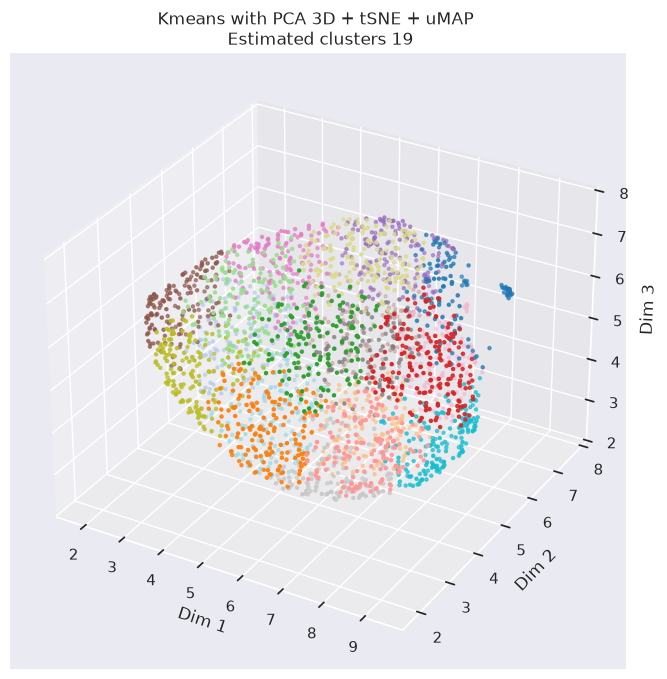

In [54]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(t)

kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(u)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(u, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(u[:,0],u[:,1],u[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("Kmeans with PCA 3D + tSNE + uMAP \n Estimated clusters 19")
plt.show()

### HDBSCAN

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Estimated number of clusters: 0
Estimated number of noise points: 2730


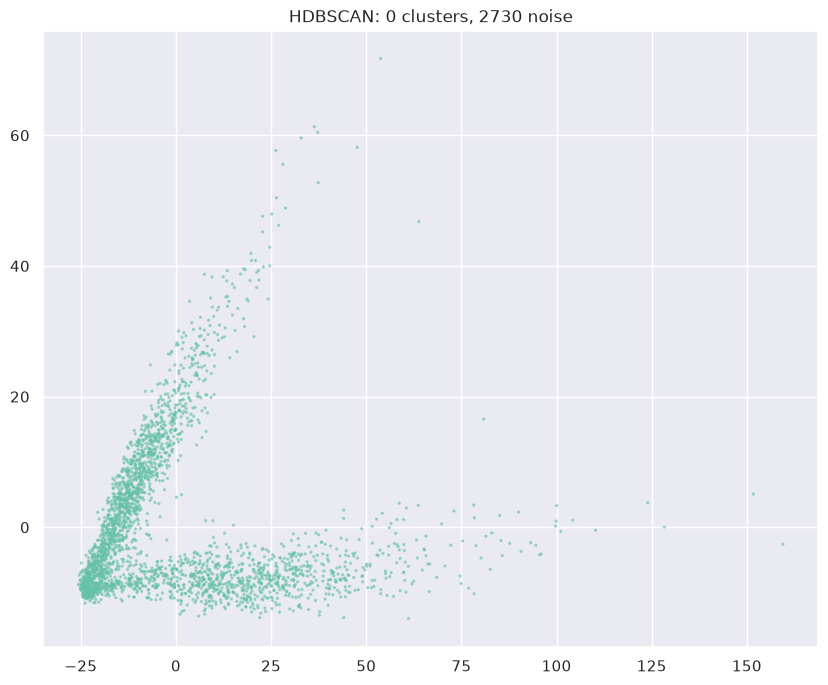

In [65]:
hdbscan = HDBSCAN(min_cluster_size=30, min_samples=5)
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
labels = hdbscan.fit_predict(scores_pca)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
plt.figure(figsize=(10, 8))
plt.scatter(scores_pca[:, 0], scores_pca[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"HDBSCAN: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Estimated number of clusters: 4
Estimated number of noise points: 1004


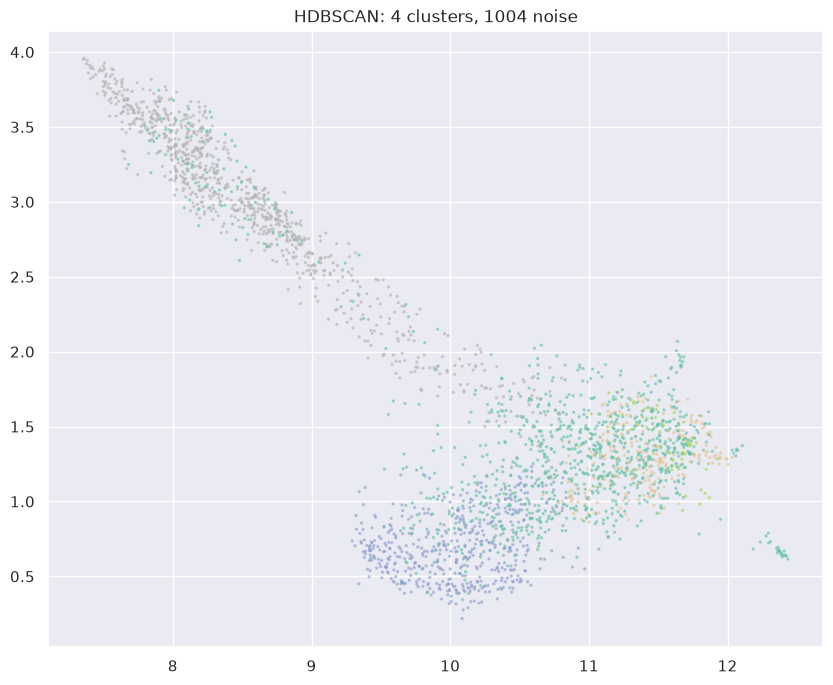

In [64]:
hdbscan = HDBSCAN(min_cluster_size=30, min_samples=5)
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
labels = hdbscan.fit_predict(u)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
plt.figure(figsize=(10, 8))
plt.scatter(u[:, 0], u[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"HDBSCAN: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


NMI:  0.33240433318077217
Silhouette Score:  0.17543084919452667
Rand Index:  0.6124432059939572
Estimated number of clusters: 4
Estimated number of noise points: 79


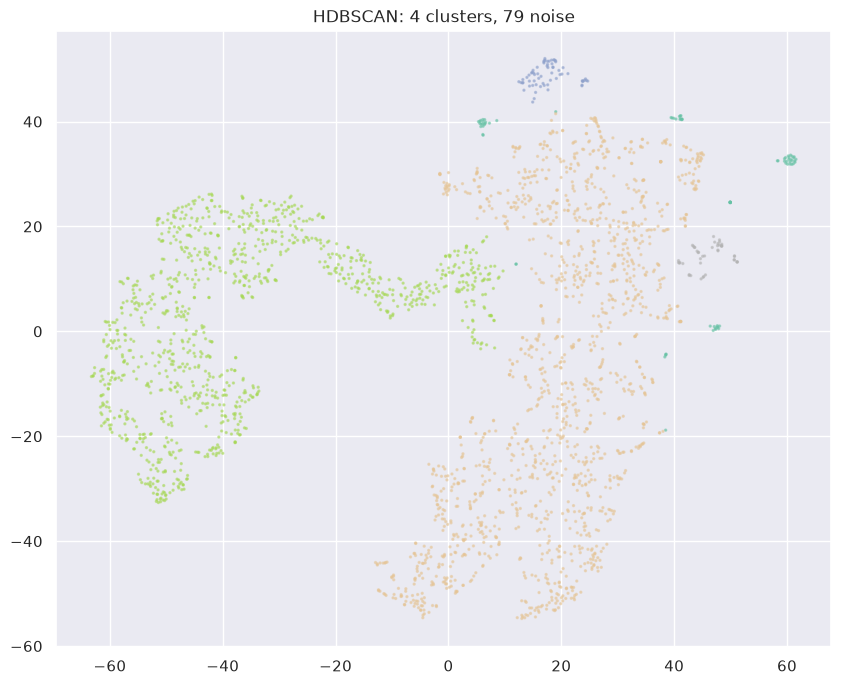

In [72]:
hdbscan = HDBSCAN(min_cluster_size=30, min_samples=5)
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
tsne = TSNE(n_components=2,random_state=3)
t = tsne.fit_transform(u)
labels = hdbscan.fit_predict(t)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(t, labels))
print("Rand Index: ", rand_score(y_true, labels))

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
plt.figure(figsize=(10, 8))
plt.scatter(t[:, 0], t[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"HDBSCAN: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


NMI:  0.34214672934882523
Silhouette Score:  0.052543893456459045
Rand Index:  0.7842790164519736
Estimated number of clusters: 19
Estimated number of noise points: 615


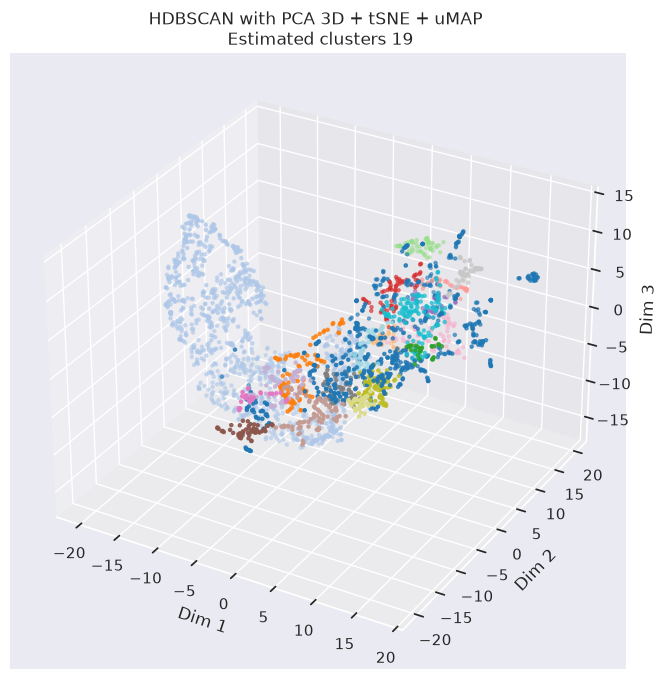

In [77]:
hdbscan = HDBSCAN(min_cluster_size=30, min_samples=3) # got this by trial and error trying to find what value gave 19 clusters
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(u)
labels = hdbscan.fit_predict(t)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(t, labels))
print("Rand Index: ", rand_score(y_true, labels))

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("HDBSCAN with PCA 3D + tSNE + uMAP \n Estimated clusters 19")
plt.show()